# Classifieur d'images : clavier mécanique vs clavier portable

## Fiche projet
- **Usage** : reconnaître, à partir d'une photo, si un clavier est un clavier mécanique ou un clavier d'ordinateur portable, pour un possible inventaire ou un e-commerce
- **Classes**
  - `clavier_mecanique` : claviers externes à switches mécaniques, touches hautes
  - `clavier_portable` : claviers intégrés aux ordinateurs portables
- **Cas ambigus** : Un clavier d'ordinateur et un clavier extra plat
- **Collecte** : images web récupérées avec `bing-image-downloader`
- **Évaluation** : partitions 70 / 15 / 15. Le test n'est consulté qu'une fois, à la fin.
- **Point de départ** : baseline « classe majoritaire », puis transfer learning ResNet-18. Metric : accuracy + rapport par classe.

Installation : `pip install -r requirements.txt`

## 0. Environnement

In [1]:
import os, random, shutil, hashlib, csv, copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.15.0+cu132 | device : cpu


## 1. Dataset

### 1.1 Collecte
Désactivée par défaut : relancer le téléchargement changerait le dataset  car Bing ne renvoie pas toujours les mêmes images

In [2]:
TELECHARGER = False

if TELECHARGER:
    from bing_image_downloader import downloader
    for requete in ["mechanical keyboard", "mechanical keyboard photo", "laptop keyboard close up"]:
        downloader.download(requete, limit=80, output_dir="raw_data",
                            adult_filter_off=False, force_replace=False)

### 1.2 Configuration


In [3]:
RAW = "raw_data"
DATA = "data"
EXTENSIONS = (".jpg", ".jpeg", ".png", ".webp")

SOURCES = {
    "clavier_mecanique": ["mechanical keyboard", "mechanical keyboard photo"],
    "clavier_portable": ["laptop keyboard close up"],
}

# Exclusions manuelles : "dossier/fichier"
EXCLUSIONS = {

}

### 1.3 Nettoyage et dédoublonnage
Les sources d'une même classe sont **fusionnées avant le découpage**. Chaque image est identifiée par son hash MD5 : une copie exacte n'est gardée qu'une fois, même si elle vient de deux requêtes différentes. Les fichiers illisibles sont écartés.

In [4]:
def hash_fichier(chemin):
    with open(chemin, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def lisible(chemin):
    try:
        with Image.open(chemin) as im:
            im.verify()
        return True
    except Exception:
        return False

images_par_classe = {}
hash_vus = set()
stats = {"doublons": 0, "exclues": 0, "illisibles": 0}

for classe, dossiers in SOURCES.items():
    images = []
    for dossier in dossiers:
        for nom in sorted(os.listdir(os.path.join(RAW, dossier))):  # sorted : ordre stable d'une machine à l'autre
            if not nom.lower().endswith(EXTENSIONS):
                continue
            if f"{dossier}/{nom}" in EXCLUSIONS:
                stats["exclues"] += 1
                continue
            chemin = os.path.join(RAW, dossier, nom)
            if not lisible(chemin):
                stats["illisibles"] += 1
                continue
            h = hash_fichier(chemin)
            if h in hash_vus:
                stats["doublons"] += 1
                continue
            hash_vus.add(h)
            images.append((dossier, nom, h))
    images_par_classe[classe] = images
    print(f"{classe} : {len(images)} images uniques")

print("Retirées :", stats)

clavier_mecanique : 118 images uniques
clavier_portable : 56 images uniques
Retirées : {'doublons': 59, 'exclues': 0, 'illisibles': 0}


### 1.4 Partitions et `metadata.csv`
Découpage 70 / 15 / 15 **par classe**, graine fixe. Les fichiers sont renommés de façon unique comme ça plus d'écrasement entre requêtes. `metadata.csv` garde pour chaque image : chemin, label, partition, requête d'origine, nom d'origine et hash.

In [5]:
if os.path.exists(DATA):
    shutil.rmtree(DATA)

random.seed(SEED)
lignes = []

for classe, images in images_par_classe.items():
    random.shuffle(images)
    n = len(images)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)
    partitions = {
        "train": images[:n_train],
        "val": images[n_train:n_train + n_val],
        "test": images[n_train + n_val:],
    }
    for part, liste in partitions.items():
        dest = os.path.join(DATA, part, classe)
        os.makedirs(dest, exist_ok=True)
        for i, (dossier, nom, h) in enumerate(liste):
            ext = os.path.splitext(nom)[1].lower()
            nouveau = f"{classe}_{part}_{i:03d}{ext}"
            shutil.copy(os.path.join(RAW, dossier, nom), os.path.join(dest, nouveau))
            lignes.append([f"{DATA}/{part}/{classe}/{nouveau}", classe, part, dossier, nom, h])

with open("metadata.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["chemin", "label", "partition", "source_requete", "fichier_origine", "md5"])
    w.writerows(lignes)

total = len(lignes)
print(f"Total : {total} images")
for part in ["train", "val", "test"]:
    n_part = sum(1 for l in lignes if l[2] == part)
    detail = ", ".join(f"{c} {sum(1 for l in lignes if l[2] == part and l[1] == c)}" for c in SOURCES)
    print(f"{part:5s} : {n_part:3d} ({n_part / total:.0%})  ->  {detail}")

Total : 174 images
train : 121 (70%)  ->  clavier_mecanique 82, clavier_portable 39
val   :  25 (14%)  ->  clavier_mecanique 17, clavier_portable 8
test  :  28 (16%)  ->  clavier_mecanique 19, clavier_portable 9


### 1.5 Contrôles
Checks :

Aucun fichier identique dans deux partitions
Contrôle visuel des labels.

In [6]:
partitions_par_hash = {}
for part in ["train", "val", "test"]:
    for racine, _, fichiers in os.walk(os.path.join(DATA, part)):
        for nom in fichiers:
            h = hash_fichier(os.path.join(racine, nom))
            partitions_par_hash.setdefault(h, set()).add(part)

fuites = [h for h, parts in partitions_par_hash.items() if len(parts) > 1]
print("Images présentes dans plusieurs partitions :", len(fuites))
assert not fuites, "Fuite entre partitions !"

Images présentes dans plusieurs partitions : 0


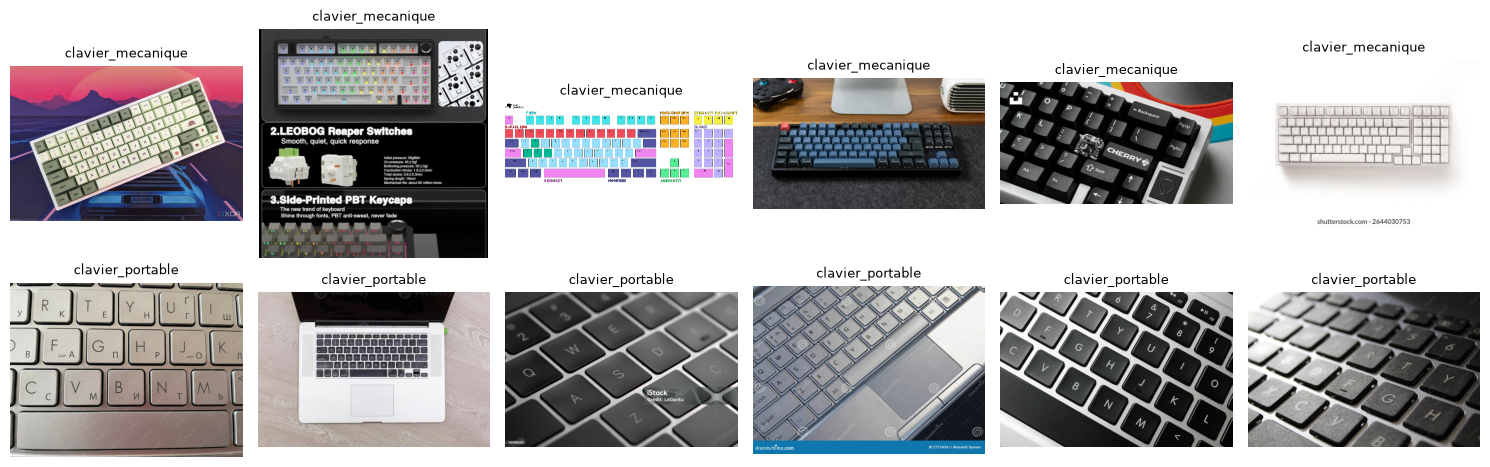

In [7]:
fig, axes = plt.subplots(len(SOURCES), 6, figsize=(15, 5))
for ligne, classe in zip(axes, SOURCES):
    dossier = os.path.join(DATA, "train", classe)
    for ax, nom in zip(ligne, random.sample(sorted(os.listdir(dossier)), 6)):
        ax.imshow(Image.open(os.path.join(dossier, nom)).convert("RGB"))
        ax.set_title(classe, fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Chargement
Preprocessing d'ImageNet

In [8]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
RESIZE, CROP = 256, 224

eval_tf = transforms.Compose([
    transforms.Resize(RESIZE),
    transforms.CenterCrop(CROP),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder(f"{DATA}/train", transform=eval_tf)
val_ds = datasets.ImageFolder(f"{DATA}/val", transform=eval_tf)
test_ds = datasets.ImageFolder(f"{DATA}/test", transform=eval_tf)

assert train_ds.class_to_idx == val_ds.class_to_idx == test_ds.class_to_idx
class_names = train_ds.classes

print("Correspondance des classes :", train_ds.class_to_idx)
print(f"Train {len(train_ds)} | Val {len(val_ds)} | Test {len(test_ds)}")

Correspondance des classes : {'clavier_mecanique': 0, 'clavier_portable': 1}
Train 121 | Val 25 | Test 28


## 3. Baseline


In [9]:
y_train = np.array(train_ds.targets)
y_val = np.array(val_ds.targets)

classe_majoritaire = np.bincount(y_train).argmax()
baseline_val = (y_val == classe_majoritaire).mean()

print(f"Classe majoritaire du train : {class_names[classe_majoritaire]}")
print(f"Accuracy baseline sur la validation : {baseline_val:.2%}")

Classe majoritaire du train : clavier_mecanique
Accuracy baseline sur la validation : 68.00%


## 4. Entraînement et journal des essais

In [10]:
def creer_modele():
    model = resnet18(weights=ResNet18_Weights.DEFAULT)
    for p in model.parameters():
        p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, len(class_names))
    return model.to(device)

def evaluer(model, loader):
    model.eval()
    y_true, y_pred, probas = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            p = torch.softmax(model(images.to(device)), dim=1).cpu()
            y_true += labels.tolist()
            y_pred += p.argmax(dim=1).tolist()
            probas += p.max(dim=1).values.tolist()
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return (y_true == y_pred).mean(), y_true, y_pred, np.array(probas)

journal = []

def lancer_essai(nom, modification, train_tf, epochs=10, lr=1e-3, batch_size=8):
    torch.manual_seed(SEED)
    ds = datasets.ImageFolder(f"{DATA}/train", transform=train_tf)
    train_loader = DataLoader(ds, batch_size=batch_size, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
    val_loader = DataLoader(val_ds, batch_size=batch_size)

    model = creer_modele()
    optimizer = torch.optim.Adam(model.fc.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    meilleur_acc, meilleure_epoch, meilleur_etat = -1.0, 0, None
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * images.size(0)
        val_acc = evaluer(model, val_loader)[0]
        print(f"[{nom}] epoch {epoch:02d} | loss train {total_loss / len(ds):.4f} | acc val {val_acc:.2%}")
        if val_acc > meilleur_acc:
            meilleur_acc, meilleure_epoch = val_acc, epoch
            meilleur_etat = copy.deepcopy(model.state_dict())

    model.load_state_dict(meilleur_etat)
    journal.append({"essai": nom, "modification": modification,
                    "meilleure_epoch": meilleure_epoch, "acc_val": meilleur_acc})
    return model

### Essai 1 : configuration de la v1, sur le dataset corrigé
ResNet-18 préentraîné, backbone figé, nouvelle tête à 2 sorties, Adam lr 1e-3, 10 epochs, sans augmentation.

In [11]:
modele_essai1 = lancer_essai("essai1", "ResNet-18 figé, sans augmentation", eval_tf)

/home/lx/Documents/2600/Année 02/IA/Projets/groupe35_classifieur/.venv/lib64/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


[essai1] epoch 01 | loss train 0.6258 | acc val 72.00%
[essai1] epoch 02 | loss train 0.4485 | acc val 88.00%
[essai1] epoch 03 | loss train 0.5041 | acc val 76.00%
[essai1] epoch 04 | loss train 0.3440 | acc val 84.00%
[essai1] epoch 05 | loss train 0.2823 | acc val 88.00%
[essai1] epoch 06 | loss train 0.2506 | acc val 80.00%
[essai1] epoch 07 | loss train 0.2200 | acc val 88.00%
[essai1] epoch 08 | loss train 0.2185 | acc val 88.00%
[essai1] epoch 09 | loss train 0.1916 | acc val 88.00%
[essai1] epoch 10 | loss train 0.1928 | acc val 96.00%


### Essai 2 : augmentations sur le train

Dans notre dataset les claviers portables sont presque tous photographié de près alors que les claviers mécaniques sont le plus souvent photographiés en entier. Le modèle peut donc atteindre un bon score en se basant juste sur le zoom de la photo plutôt que sur le clavier. Le recadrage aléatoire garde un morceau de l'image entre 40% et 100% de sa surface et l'agrandit. Pendant l'entraînement les claviers mécaniques apparaissent donc eux aussi avec le zoom variable. Pour faire baisser la loss le modèle doit s'appuyer sur des indices qui restent visibles quel que soit le cadrage (hauteur des touches)

In [12]:
train_tf_aug = transforms.Compose([
    transforms.RandomResizedCrop(CROP, scale=(0.4, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

modele_essai2 = lancer_essai("essai2", "Augmentations : recadrage aléatoire, flip, couleurs", train_tf_aug)

[essai2] epoch 01 | loss train 0.6321 | acc val 80.00%
[essai2] epoch 02 | loss train 0.4795 | acc val 88.00%
[essai2] epoch 03 | loss train 0.5370 | acc val 68.00%
[essai2] epoch 04 | loss train 0.3608 | acc val 80.00%
[essai2] epoch 05 | loss train 0.3074 | acc val 84.00%
[essai2] epoch 06 | loss train 0.2727 | acc val 84.00%
[essai2] epoch 07 | loss train 0.2574 | acc val 92.00%
[essai2] epoch 08 | loss train 0.2415 | acc val 88.00%
[essai2] epoch 09 | loss train 0.2297 | acc val 88.00%
[essai2] epoch 10 | loss train 0.2163 | acc val 96.00%


### Journal

In [13]:
print(f"{'essai':10s} {'acc val':>8s} {'epoch':>6s}  modification")
print(f"{'baseline':10s} {baseline_val:8.2%} {'-':>6s}  classe majoritaire du train")
for e in journal:
    print(f"{e['essai']:10s} {e['acc_val']:8.2%} {e['meilleure_epoch']:6d}  {e['modification']}")

essai       acc val  epoch  modification
baseline     68.00%      -  classe majoritaire du train
essai1       96.00%     10  ResNet-18 figé, sans augmentation
essai2       96.00%     10  Augmentations : recadrage aléatoire, flip, couleurs


#### Historique des erreurs sur les versions du notebook

Les 2 requêtes mechanical keyboard et mechanical keyboard photo ont téléchargé 37 images identiques. Comme le code découpait chaque requête séparément en train/val/test une même image pouvait tomber plusieurs fois dans 2 partitions différentes.

Le 96% était donc un résultat surrestimé, parce que pour certaines images de test, le modèle les connaissait déjà.

Il y avait aussi le problème de fichiers ayant les mêmes noms entre 2 requêtes, les copies s'écrasaient donc entre elles et des images disparaissaient.

## 5. Test final (consulté une seule fois)
On retient l'essai qui a le meilleur score de validation.

In [14]:
choix = max(journal, key=lambda e: e["acc_val"])
modele_final = {"essai1": modele_essai1, "essai2": modele_essai2}[choix["essai"]]
print("Modèle retenu :", choix)

Modèle retenu : {'essai': 'essai1', 'modification': 'ResNet-18 figé, sans augmentation', 'meilleure_epoch': 10, 'acc_val': np.float64(0.96)}


Accuracy TEST : 82.14%  (baseline sur le test : 67.86%)

                   precision    recall  f1-score   support

clavier_mecanique       0.94      0.79      0.86        19
 clavier_portable       0.67      0.89      0.76         9

         accuracy                           0.82        28
        macro avg       0.80      0.84      0.81        28
     weighted avg       0.85      0.82      0.83        28



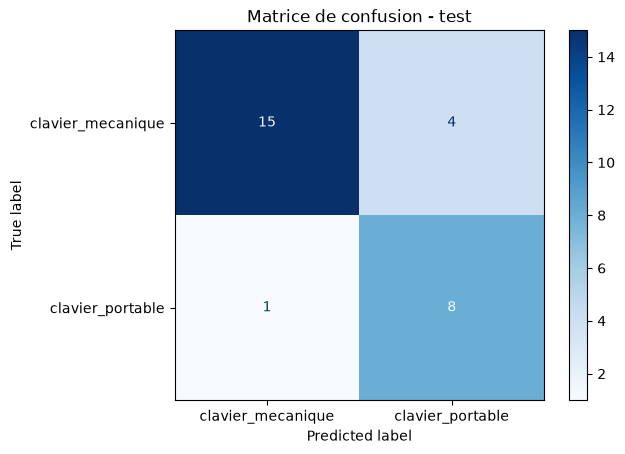

In [15]:
test_loader = DataLoader(test_ds, batch_size=8)
test_acc, y_true, y_pred, probas = evaluer(modele_final, test_loader)

print(f"Accuracy TEST : {test_acc:.2%}  (baseline sur le test : {(y_true == classe_majoritaire).mean():.2%})\n")
print(classification_report(y_true, y_pred, target_names=class_names))

ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=class_names, cmap="Blues")
plt.title("Matrice de confusion - test")
plt.show()

## 6. Analyse : réussites et erreurs


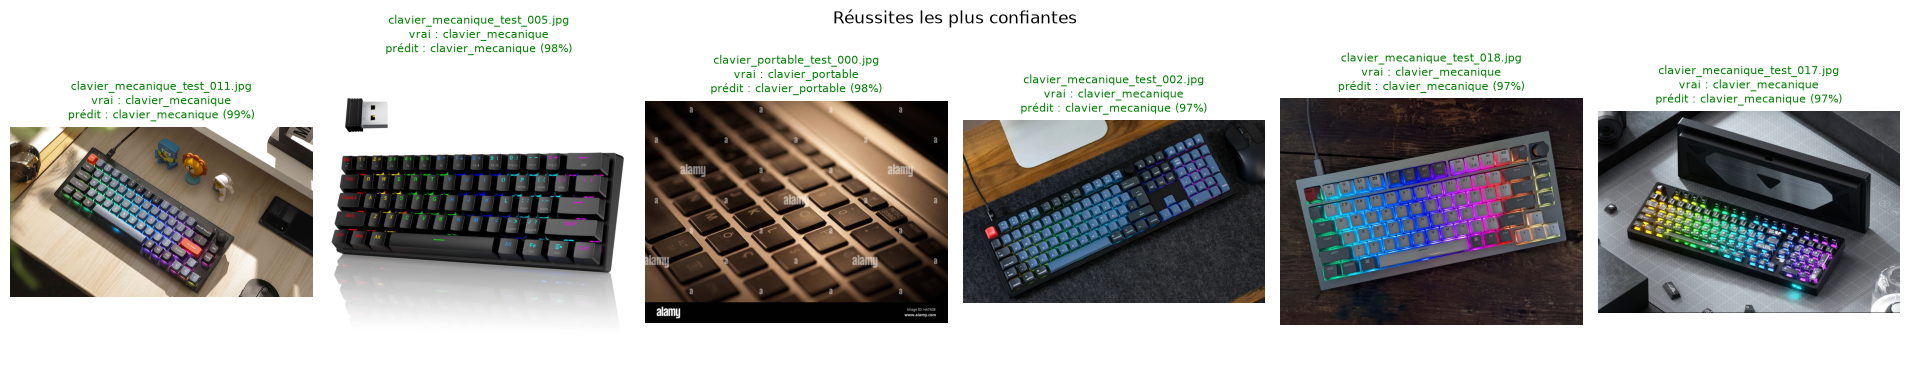

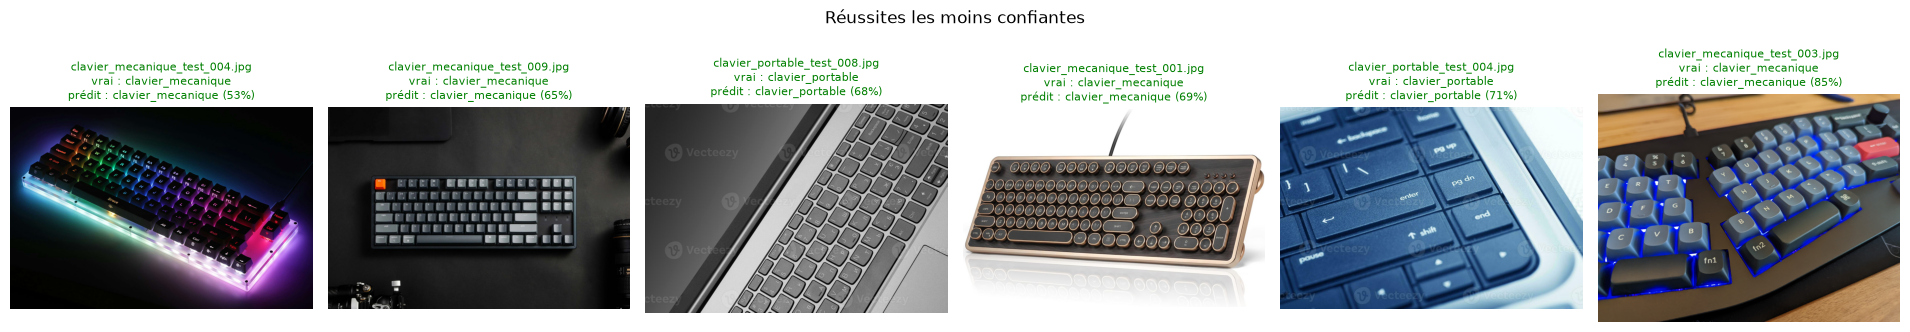

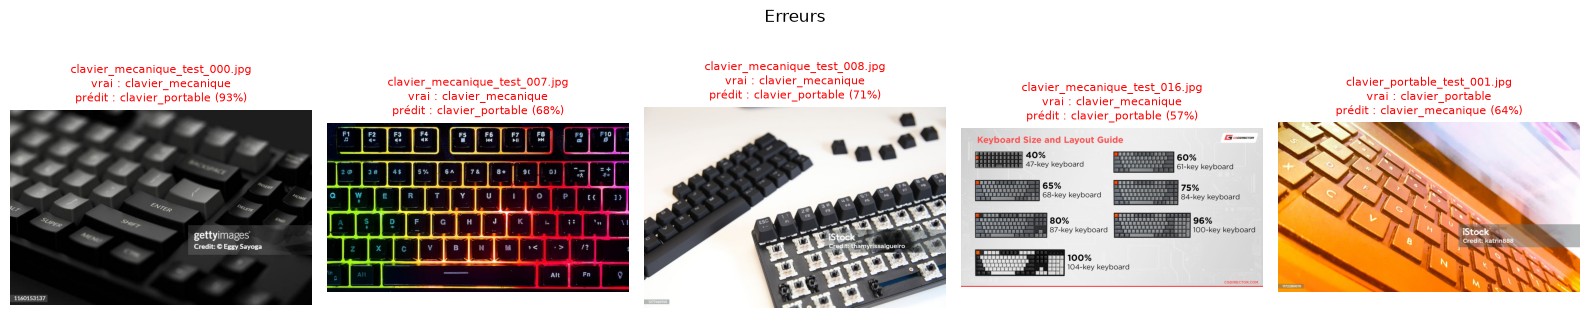

In [16]:
def afficher(indices, titre, maxi=8):
    indices = list(indices)[:maxi]
    if not indices:
        print(f"{titre} : aucune image")
        return
    fig, axes = plt.subplots(1, len(indices), figsize=(3.2 * len(indices), 3.8), squeeze=False)
    for ax, i in zip(axes[0], indices):
        chemin = test_ds.samples[i][0]
        ax.imshow(Image.open(chemin).convert("RGB"))
        juste = y_true[i] == y_pred[i]
        ax.set_title(f"{os.path.basename(chemin)}\nvrai : {class_names[y_true[i]]}\n"
                     f"prédit : {class_names[y_pred[i]]} ({probas[i]:.0%})",
                     fontsize=8, color="green" if juste else "red")
        ax.axis("off")
    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()

justes = np.where(y_true == y_pred)[0]
erreurs = np.where(y_true != y_pred)[0]

afficher(justes[np.argsort(-probas[justes])], "Réussites les plus confiantes", maxi=6)
afficher(justes[np.argsort(probas[justes])], "Réussites les moins confiantes", maxi=6)
afficher(erreurs, "Erreurs")

**Commentaires :**
4 erreurs sur 5 sont des claviers mécaniques prédits comme portables souvent en gros plan. Une erreur n'est pas une photo mais une infographie restée dans le dataset

## 7. Modèle rechargeable

In [17]:
checkpoint = {
    "architecture": "resnet18",
    "state_dict": modele_final.state_dict(),
    "class_to_idx": train_ds.class_to_idx,
    "preprocessing": {"resize": RESIZE, "crop": CROP, "mean": MEAN, "std": STD},
    "essai": choix["essai"],
}
torch.save(checkpoint, "modele.pt")
print("Modèle sauvegardé : modele.pt")

Modèle sauvegardé : modele.pt


In [18]:
def charger_modele(chemin="modele.pt"):
    ckpt = torch.load(chemin, map_location="cpu")
    model = resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, len(ckpt["class_to_idx"]))
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    pp = ckpt["preprocessing"]
    tf = transforms.Compose([
        transforms.Resize(pp["resize"]),
        transforms.CenterCrop(pp["crop"]),
        transforms.ToTensor(),
        transforms.Normalize(pp["mean"], pp["std"]),
    ])
    idx_to_class = {v: k for k, v in ckpt["class_to_idx"].items()}
    return model, tf, idx_to_class

def predire(chemin_image, model, tf, idx_to_class):
    x = tf(Image.open(chemin_image).convert("RGB")).unsqueeze(0)
    with torch.no_grad():
        p = torch.softmax(model(x), dim=1)[0]
    return idx_to_class[int(p.argmax())], float(p.max())

modele_recharge, tf_recharge, idx_to_class = charger_modele()
exemple = test_ds.samples[0][0]
classe, proba = predire(exemple, modele_recharge, tf_recharge, idx_to_class)
print(f"{exemple} -> {classe} ({proba:.0%})")

data/test/clavier_mecanique/clavier_mecanique_test_000.jpg -> clavier_portable (93%)


## 8. Limites et prochaines expériences

**Limites** : 
- Les pc sont presques tous en gros plan et les mécaniques sont en entier.
- Toutes les images viennent du web donc le modèle n'a jamais vu d'image réelle d'un téléphone

**Prochaine expérience** : 
- Il faudrait en premier lieu tester notre modèle sur nos propres photos entre entier et gros plan, pour vérifier que le modèle marche hors des banques d'images du web 